# Experiment 4 (`ex004`): MNIST Digit Regression ($y \in [0, 9]$) vs. Classification with Deep VIB ($K = 2$)

本ノートブックでは，追加実験として MNIST の手書き数字画像 $x \in [-1, 1]^{784}$ を入力し，その画像に写る数字を連続的な数値 $y \in [0, 9]$ として予測する**回帰タスク (Regression Task)** に Deep Variational Information Bottleneck (Deep VIB) を適用する．

特に `ex002` と同様にボトルネック次元を $K = 2$（2次元完全共分散ガウス分布 $p(z|x) = \mathcal{N}(z \mid \mu(x), \Sigma(x))$）に設定し，**分類タスク（10クラス交差エントロピー損失）** と **回帰タスク（ガウス変分デコーダによる平均二乗誤差 MSE 損失）** の間で，学習される 2次元潜在空間 $Z$ の幾何学的構造・トポロジー・不確実性楕円がどのように変化するかを散布図により徹底比較する．

In [1]:
import os
import time
import numpy as np
import torch
import matplotlib.pyplot as plt

from model import (
    DeepVIBRegression2DFullCov,
    DeepVIBClassification2DFullCov,
    DeepVIBRegressionDiag,
)
from utils import (
    set_seed,
    load_mnist_gpu,
    train_vib_regression_2d,
    train_vib_classification_2d,
    evaluate_vib_regression_2d,
    evaluate_vib_classification_2d,
    plot_latent_scatter_on_ax,
)

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")

os.makedirs("../report/img", exist_ok=True)
train_x, train_y, test_x, test_y = load_mnist_gpu("../datasets", device=device)
var_y_test = torch.var(test_y.float(), unbiased=False).item()
print(f"Train: {train_x.shape}, Test: {test_x.shape}, Test Target Var(Y): {var_y_test:.4f}")

Using device: cuda (NVIDIA GeForce RTX 4080)
Train: torch.Size([60000, 784]), Test: torch.Size([10000, 784]), Test Target Var(Y): 8.3852


In [2]:
# 1. 比較ベースライン: 分類タスク (Classification, K=2 Full-Covariance Gaussian)
betas_cls = [1e-3, 1e-2, 1e-1, 1e0]
cls_models = {}
cls_histories = {}
cls_metrics = {}

t0 = time.time()
for beta in betas_cls:
    set_seed(42)
    model_c = DeepVIBClassification2DFullCov(
        input_dim=784, hidden_dim=1024, latent_dim=2, num_classes=10, sigma_bias=-5.0, offdiag_scale=1e-2
    ).to(device)
    ema_c, hist_c = train_vib_classification_2d(
        model_c, train_x, train_y, test_x, test_y,
        beta=beta, epochs=200, batch_size=100, lr=1e-4,
        lr_decay_factor=0.97, lr_decay_every=2, ema_decay=0.999,
        record_every=50, desc=f"Cls K=2 (beta={beta:.0e})"
    )
    cls_models[beta] = ema_c
    cls_histories[beta] = hist_c
    cls_metrics[beta] = evaluate_vib_classification_2d(ema_c, test_x, test_y, mc_samples=12)

print(f"\nClassification K=2 finished in {time.time() - t0:.1f}s")
print(f"{'Beta':>8s} | {'Err(1shot)':>10s} | {'Err(12MC)':>10s} | {'I(Z,X)[b]':>10s} | {'I(Z,Y)[b]':>10s} | {'PC1 Ratio':>10s} | {'|Spearman|':>10s}")
print("-" * 82)
for beta in betas_cls:
    m = cls_metrics[beta]
    print(f"{beta:8.0e} | {m['err_1shot']*100:9.2f}% | {m['err_mc']*100:9.2f}% | {m['izx_bits']:10.2f} | {m['izy_bits']:10.3f} | {m['pc1_ratio']:10.4f} | {m['abs_spearman']:10.4f}")


Classification K=2 finished in 147.5s
    Beta | Err(1shot) |  Err(12MC) |  I(Z,X)[b] |  I(Z,Y)[b] |  PC1 Ratio | |Spearman|
----------------------------------------------------------------------------------
   1e-03 |      3.44% |      3.37% |      61.23 |      3.010 |     0.5360 |     0.2970
   1e-02 |      3.50% |      3.28% |      14.33 |      3.032 |     0.5957 |     0.2000
   1e-01 |      4.73% |      3.40% |       5.60 |      2.786 |     0.5058 |     0.4545
   1e+00 |     84.75% |     72.86% |       0.07 |      0.131 |     0.6165 |     0.8545


Cls K=2 (beta=1e+00): 100%|##########| 200/200 [00:37<00:00,  5.33it/s, err_mc=72.65%, I(Z,X)=0.1b]


In [3]:
# 2. 回帰タスク (Regression, K=2 Full-Covariance Gaussian, 線形デコーダ fd(z) = w^T z + b)
betas_reg = [1e-3, 1e-2, 1e-1, 1e0, 1e1]
reg_lin_models = {}
reg_lin_histories = {}
reg_lin_metrics = {}

t0 = time.time()
for beta in betas_reg:
    set_seed(42)
    model_r = DeepVIBRegression2DFullCov(
        input_dim=784, hidden_dim=1024, latent_dim=2, sigma_bias=-5.0, offdiag_scale=1e-2, decoder_type="linear"
    ).to(device)
    ema_r, hist_r = train_vib_regression_2d(
        model_r, train_x, train_y, test_x, test_y,
        beta=beta, epochs=200, batch_size=100, lr=1e-4,
        lr_decay_factor=0.97, lr_decay_every=2, ema_decay=0.999,
        record_every=25, desc=f"Reg-Lin K=2 (beta={beta:.0e})"
    )
    reg_lin_models[beta] = ema_r
    reg_lin_histories[beta] = hist_r
    reg_lin_metrics[beta] = evaluate_vib_regression_2d(ema_r, test_x, test_y, mc_samples=12)

print(f"\nRegression Linear K=2 finished in {time.time() - t0:.1f}s")
print(f"{'Beta':>8s} | {'RMSE(1sh)':>9s} | {'RMSE(MC)':>8s} | {'MAE(MC)':>7s} | {'R^2(MC)':>7s} | {'RoundErr':>8s} | {'I(Z,X)':>7s} | {'I(Z,Y)':>6s} | {'PC1Ratio':>8s} | {'|Spearm|':>8s}")
print("-" * 102)
for beta in betas_reg:
    m = reg_lin_metrics[beta]
    print(f"{beta:8.0e} | {m['rmse_1shot']:9.4f} | {m['rmse_mc']:8.4f} | {m['mae_mc']:7.4f} | {m['r2_mc']:7.4f} | {m['err_round_mc']*100:7.2f}% | {m['izx_bits']:7.2f} | {m['izy_bits']:6.3f} | {m['pc1_ratio']:8.4f} | {m['abs_spearman']:8.4f}")


Regression Linear K=2 finished in 181.5s
    Beta | RMSE(1sh) | RMSE(MC) | MAE(MC) | R^2(MC) | RoundErr |  I(Z,X) | I(Z,Y) | PC1Ratio | |Spearm|
------------------------------------------------------------------------------------------------------
   1e-03 |    0.5429 |   0.5422 |  0.2213 |  0.9649 |    8.86% |   18.36 |  2.417 |   0.9982 |   1.0000
   1e-02 |    0.5533 |   0.5464 |  0.2176 |  0.9644 |    8.60% |    6.97 |  2.406 |   0.9980 |   1.0000
   1e-01 |    0.6005 |   0.5426 |  0.2250 |  0.9649 |    8.16% |    3.75 |  2.416 |   0.9987 |   1.0000
   1e+00 |    1.0085 |   0.6332 |  0.3799 |  0.9522 |   21.68% |    1.88 |  2.193 |   0.9996 |   1.0000
   1e+01 |    2.6337 |   2.1927 |  1.8700 |  0.4266 |   86.36% |    0.22 |  0.401 |   0.9999 |   1.0000


Reg-Lin K=2 (beta=1e+01): 100%|##########| 200/200 [00:36<00:00,  5.49it/s, RMSE=2.194, I(Z,X)=0.2b]


In [4]:
# 3. 回帰タスク (Regression, K=2 非線形MLPデコーダ 2->64->1) および 高次元 K=256 回帰モデル
betas_mlp = [1e-3, 1e-2, 1e-1, 1e0]
reg_mlp_models = {}
reg_mlp_histories = {}
reg_mlp_metrics = {}

t0 = time.time()
for beta in betas_mlp:
    set_seed(42)
    model_m = DeepVIBRegression2DFullCov(
        input_dim=784, hidden_dim=1024, latent_dim=2, sigma_bias=-5.0, offdiag_scale=1e-2, decoder_type="mlp"
    ).to(device)
    ema_m, hist_m = train_vib_regression_2d(
        model_m, train_x, train_y, test_x, test_y,
        beta=beta, epochs=200, batch_size=100, lr=1e-4,
        lr_decay_factor=0.97, lr_decay_every=2, ema_decay=0.999,
        record_every=50, desc=f"Reg-MLP K=2 (beta={beta:.0e})"
    )
    reg_mlp_models[beta] = ema_m
    reg_mlp_histories[beta] = hist_m
    reg_mlp_metrics[beta] = evaluate_vib_regression_2d(ema_m, test_x, test_y, mc_samples=12)

# K=256 対角ガウス回帰モデル (beta = 1e-3, 1e-2, 1e-1)
betas_k256 = [1e-3, 1e-2, 1e-1]
reg_k256_metrics = {}
for beta in betas_k256:
    set_seed(42)
    model_256 = DeepVIBRegressionDiag(input_dim=784, hidden_dim=1024, latent_dim=256, sigma_bias=-5.0).to(device)
    ema_256, _ = train_vib_regression_2d(
        model_256, train_x, train_y, test_x, test_y,
        beta=beta, epochs=200, batch_size=100, lr=1e-4,
        lr_decay_factor=0.97, lr_decay_every=2, ema_decay=0.999,
        record_every=100, desc=f"Reg-Diag K=256 (beta={beta:.0e})"
    )
    reg_k256_metrics[beta] = evaluate_vib_regression_2d(ema_256, test_x, test_y, mc_samples=12)

print(f"\nRegression MLP (K=2) & Diag (K=256) finished in {time.time() - t0:.1f}s")
print("=== Regression MLP (K=2) ===")
for beta in betas_mlp:
    m = reg_mlp_metrics[beta]
    print(f"beta={beta:7.0e} | RMSE(MC)={m['rmse_mc']:.4f} | MAE={m['mae_mc']:.4f} | R2={m['r2_mc']:.4f} | RoundErr={m['err_round_mc']*100:.2f}% | I(Z,X)={m['izx_bits']:.2f}b | PC1={m['pc1_ratio']:.4f} | |Spearman|={m['abs_spearman']:.4f}")
print("\n=== Regression Diag (K=256) ===")
for beta in betas_k256:
    m = reg_k256_metrics[beta]
    print(f"beta={beta:7.0e} | RMSE(1sh)={m['rmse_1shot']:.4f} | RMSE(MC)={m['rmse_mc']:.4f} | MAE={m['mae_mc']:.4f} | R2={m['r2_mc']:.4f} | RoundErr={m['err_round_mc']*100:.2f}% | I(Z,X)={m['izx_bits']:.2f}b")


Regression MLP (K=2) & Diag (K=256) finished in 265.0s
=== Regression MLP (K=2) ===
beta=  1e-03 | RMSE(MC)=0.5007 | MAE=0.1806 | R2=0.9701 | RoundErr=7.30% | I(Z,X)=10.21b | PC1=0.7413 | |Spearman|=1.0000
beta=  1e-02 | RMSE(MC)=0.5174 | MAE=0.1860 | R2=0.9681 | RoundErr=7.16% | I(Z,X)=5.50b | PC1=0.7406 | |Spearman|=1.0000
beta=  1e-01 | RMSE(MC)=0.5455 | MAE=0.2348 | R2=0.9645 | RoundErr=9.27% | I(Z,X)=3.31b | PC1=0.9976 | |Spearman|=1.0000
beta=  1e+00 | RMSE(MC)=0.6425 | MAE=0.4008 | R2=0.9508 | RoundErr=26.87% | I(Z,X)=1.68b | PC1=0.9993 | |Spearman|=1.0000

=== Regression Diag (K=256) ===
beta=  1e-03 | RMSE(1sh)=0.5847 | RMSE(MC)=0.5761 | MAE=0.2659 | R2=0.9604 | RoundErr=12.10% | I(Z,X)=54.59b
beta=  1e-02 | RMSE(1sh)=0.5820 | RMSE(MC)=0.5519 | MAE=0.2364 | R2=0.9637 | RoundErr=9.80% | I(Z,X)=17.13b
beta=  1e-01 | RMSE(1sh)=0.6659 | RMSE(MC)=0.5587 | MAE=0.2519 | R2=0.9628 | RoundErr=9.84% | I(Z,X)=5.58b


Reg-Diag K=256 (beta=1e-01): 100%|##########| 200/200 [00:37<00:00,  5.34it/s, RMSE=0.558, I(Z,X)=5.6b]


Saved ../report/img/ex004_cls_vs_reg_scatter.png


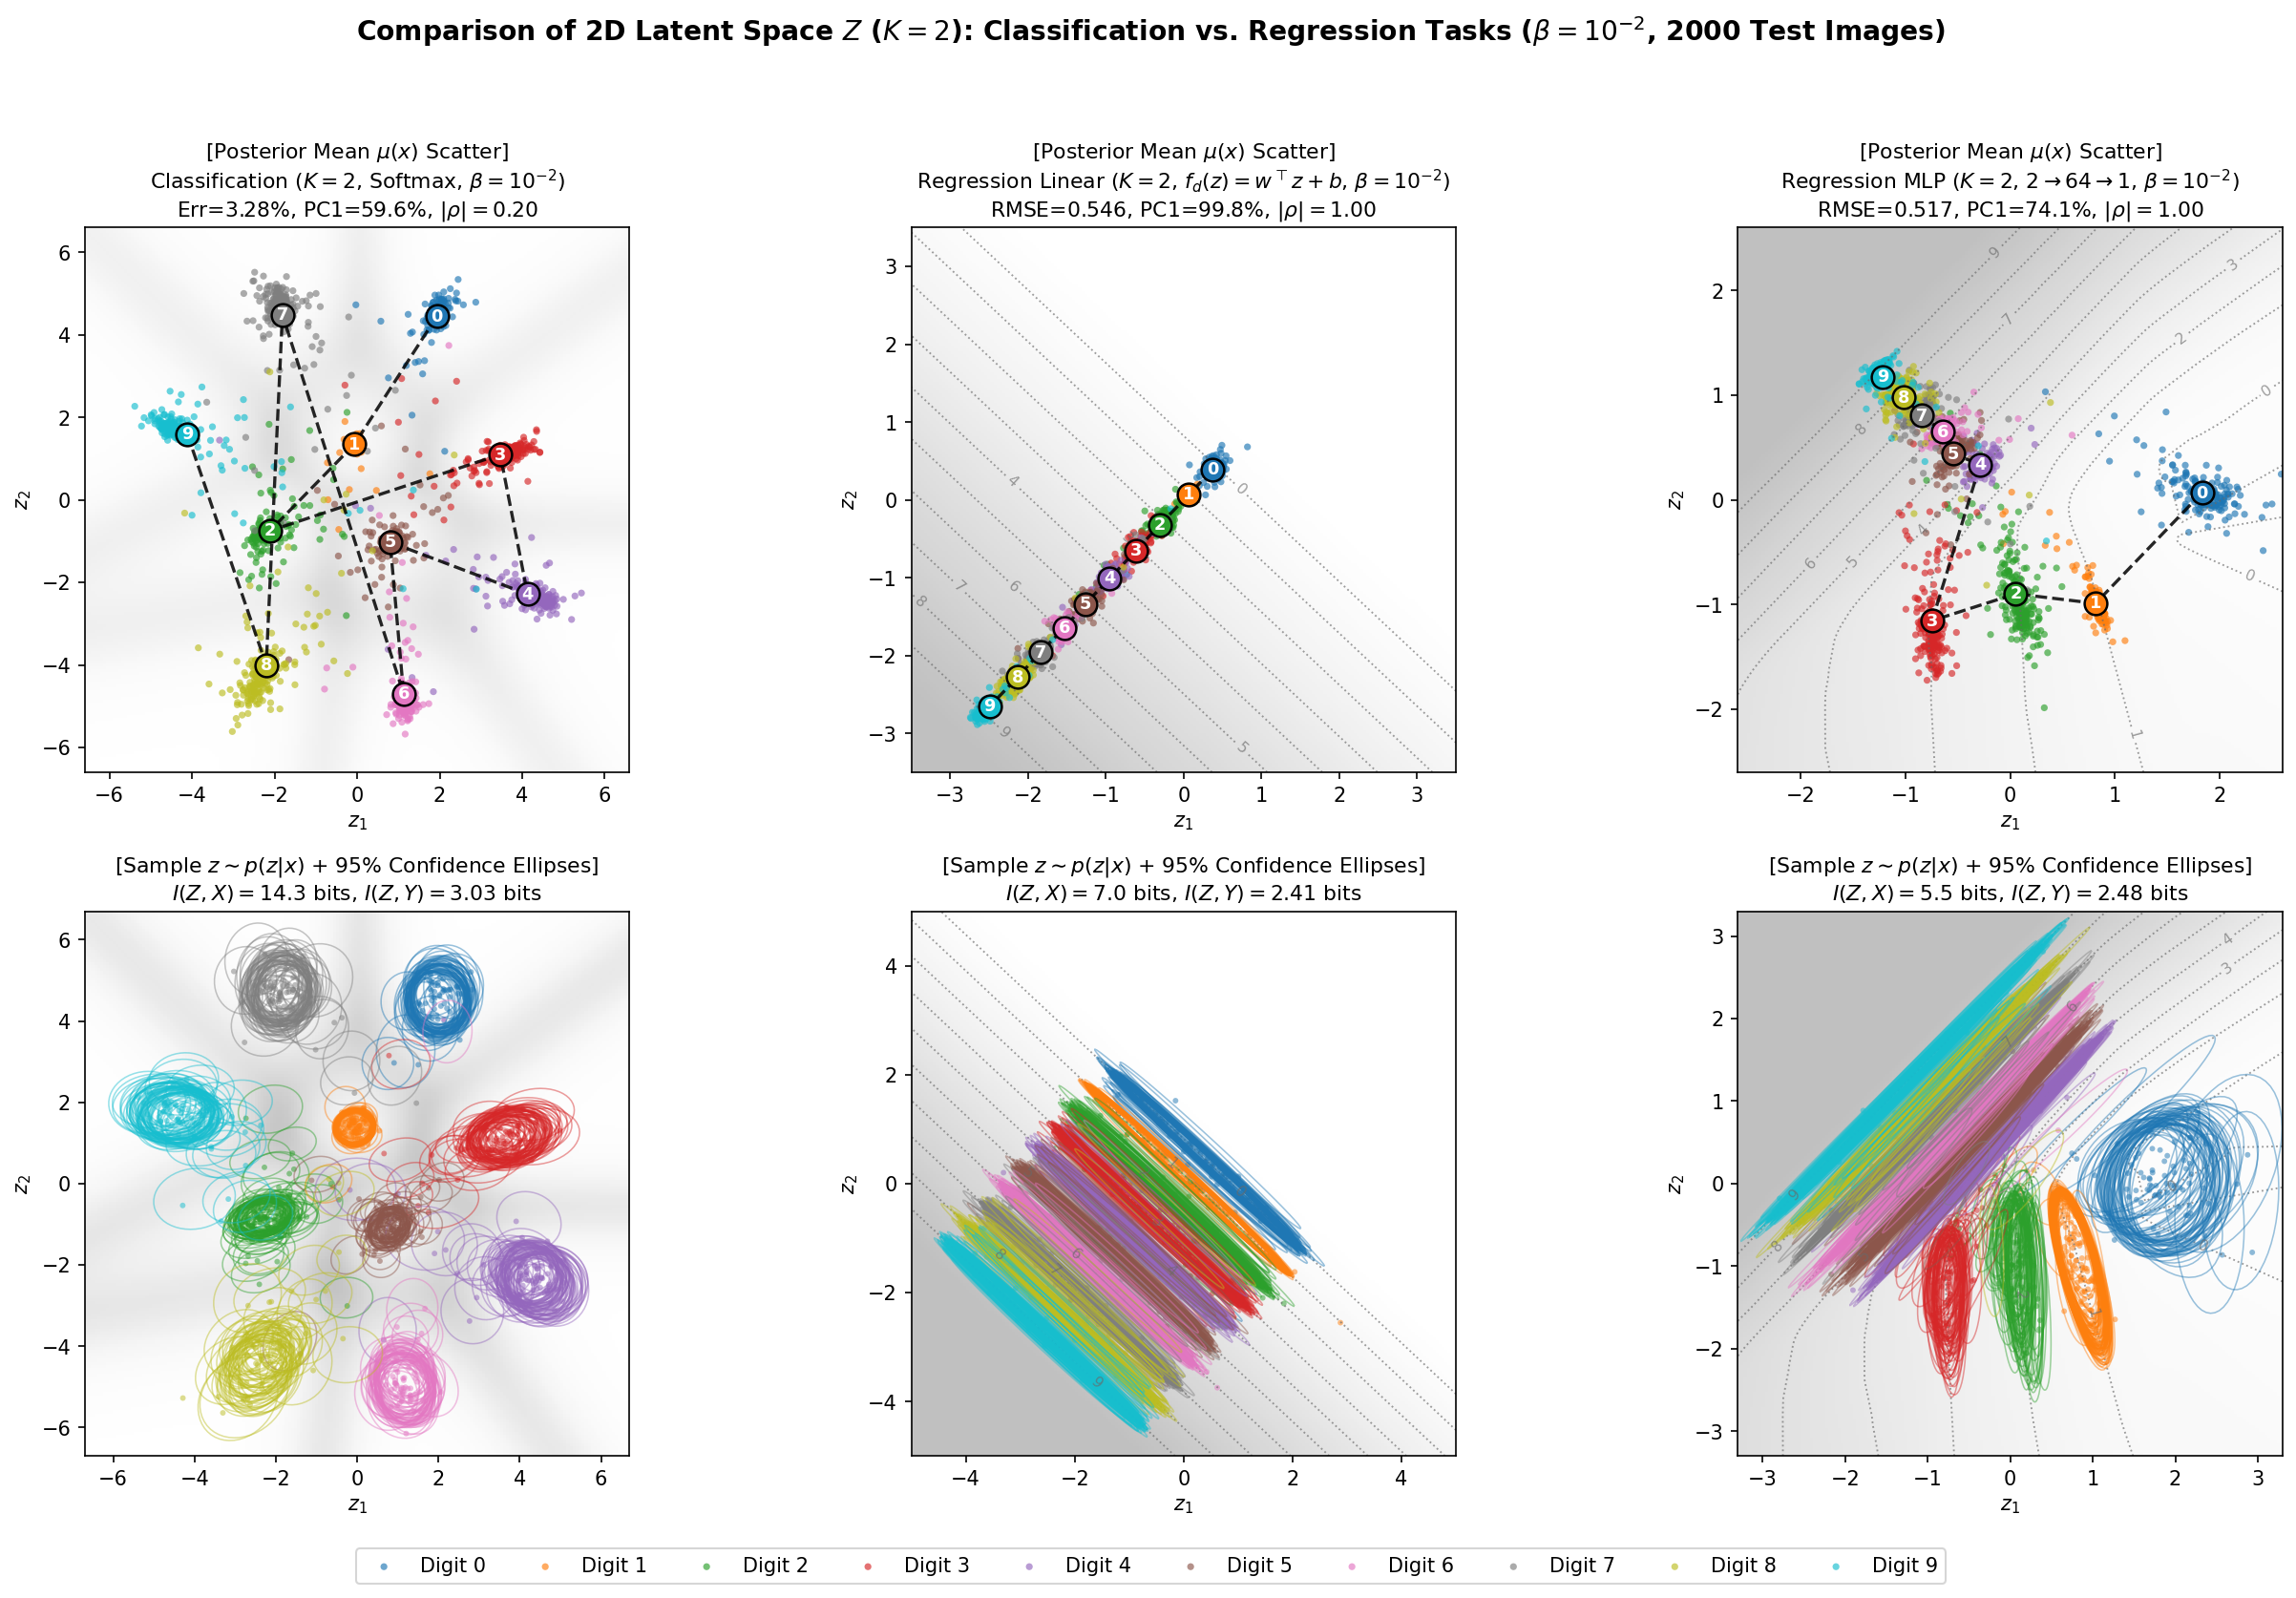

In [5]:
# 4. 図1: 分類タスク vs 回帰タスク (線形デコーダ / MLPデコーダ) の2次元潜在空間 Z 散布図の直接比較 (beta = 1e-2)
beta_vis = 1e-2
fig, axes = plt.subplots(2, 3, figsize=(17.5, 11.2), dpi=180)

configs = [
    (
        cls_models[beta_vis],
        "classification",
        cls_metrics[beta_vis],
        f"Classification ($K=2$, Softmax, $\\beta=10^{{-2}}$)\nErr={cls_metrics[beta_vis]['err_mc']*100:.2f}%, PC1={cls_metrics[beta_vis]['pc1_ratio']*100:.1f}%, $|\\rho|={cls_metrics[beta_vis]['abs_spearman']:.2f}$"
    ),
    (
        reg_lin_models[beta_vis],
        "regression",
        reg_lin_metrics[beta_vis],
        f"Regression Linear ($K=2$, $f_d(z)=w^\\top z+b$, $\\beta=10^{{-2}}$)\nRMSE={reg_lin_metrics[beta_vis]['rmse_mc']:.3f}, PC1={reg_lin_metrics[beta_vis]['pc1_ratio']*100:.1f}%, $|\\rho|={reg_lin_metrics[beta_vis]['abs_spearman']:.2f}$"
    ),
    (
        reg_mlp_models[beta_vis],
        "regression",
        reg_mlp_metrics[beta_vis],
        f"Regression MLP ($K=2$, $2\\to 64\\to 1$, $\\beta=10^{{-2}}$)\nRMSE={reg_mlp_metrics[beta_vis]['rmse_mc']:.3f}, PC1={reg_mlp_metrics[beta_vis]['pc1_ratio']*100:.1f}%, $|\\rho|={reg_mlp_metrics[beta_vis]['abs_spearman']:.2f}$"
    ),
]

for col, (mdl, t_type, met, top_title) in enumerate(configs):
    # Row 0: 事後平均 mu(x) の散布図 + クラス重心 0->1->...->9 の軌跡
    plot_latent_scatter_on_ax(
        axes[0, col], mdl, test_x, test_y,
        task_type=t_type, plot_mode="mean_scatter", num_images=2000,
        title=f"[Posterior Mean $\\mu(x)$ Scatter]\n{top_title}"
    )
    # Row 1: サンプル z ~ p(z|x) の散布図 + 95%信頼楕円 + 背景フィールド
    plot_latent_scatter_on_ax(
        axes[1, col], mdl, test_x, test_y,
        task_type=t_type, plot_mode="sample_and_ellipse", num_images=1000,
        title=f"[Sample $z \\sim p(z|x)$ + 95% Confidence Ellipses]\n$I(Z,X)={met['izx_bits']:.1f}$ bits, $I(Z,Y)={met['izy_bits']:.2f}$ bits"
    )

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(
    handles, [f"Digit {l}" for l in labels],
    loc="lower center", ncol=10, frameon=True, fontsize=10, bbox_to_anchor=(0.5, 0.005)
)
fig.suptitle(
    "Comparison of 2D Latent Space $Z$ ($K=2$): Classification vs. Regression Tasks ($\\beta = 10^{-2}$, 2000 Test Images)",
    fontsize=13.5, fontweight="bold", y=0.99
)
plt.tight_layout(rect=[0.0, 0.04, 1.0, 0.96])
out_fig1 = "../report/img/ex004_cls_vs_reg_scatter.png"
plt.savefig(out_fig1, dpi=180)
plt.show()
print(f"Saved {out_fig1}")

Saved ../report/img/ex004_reg_beta_scatter_grid.png


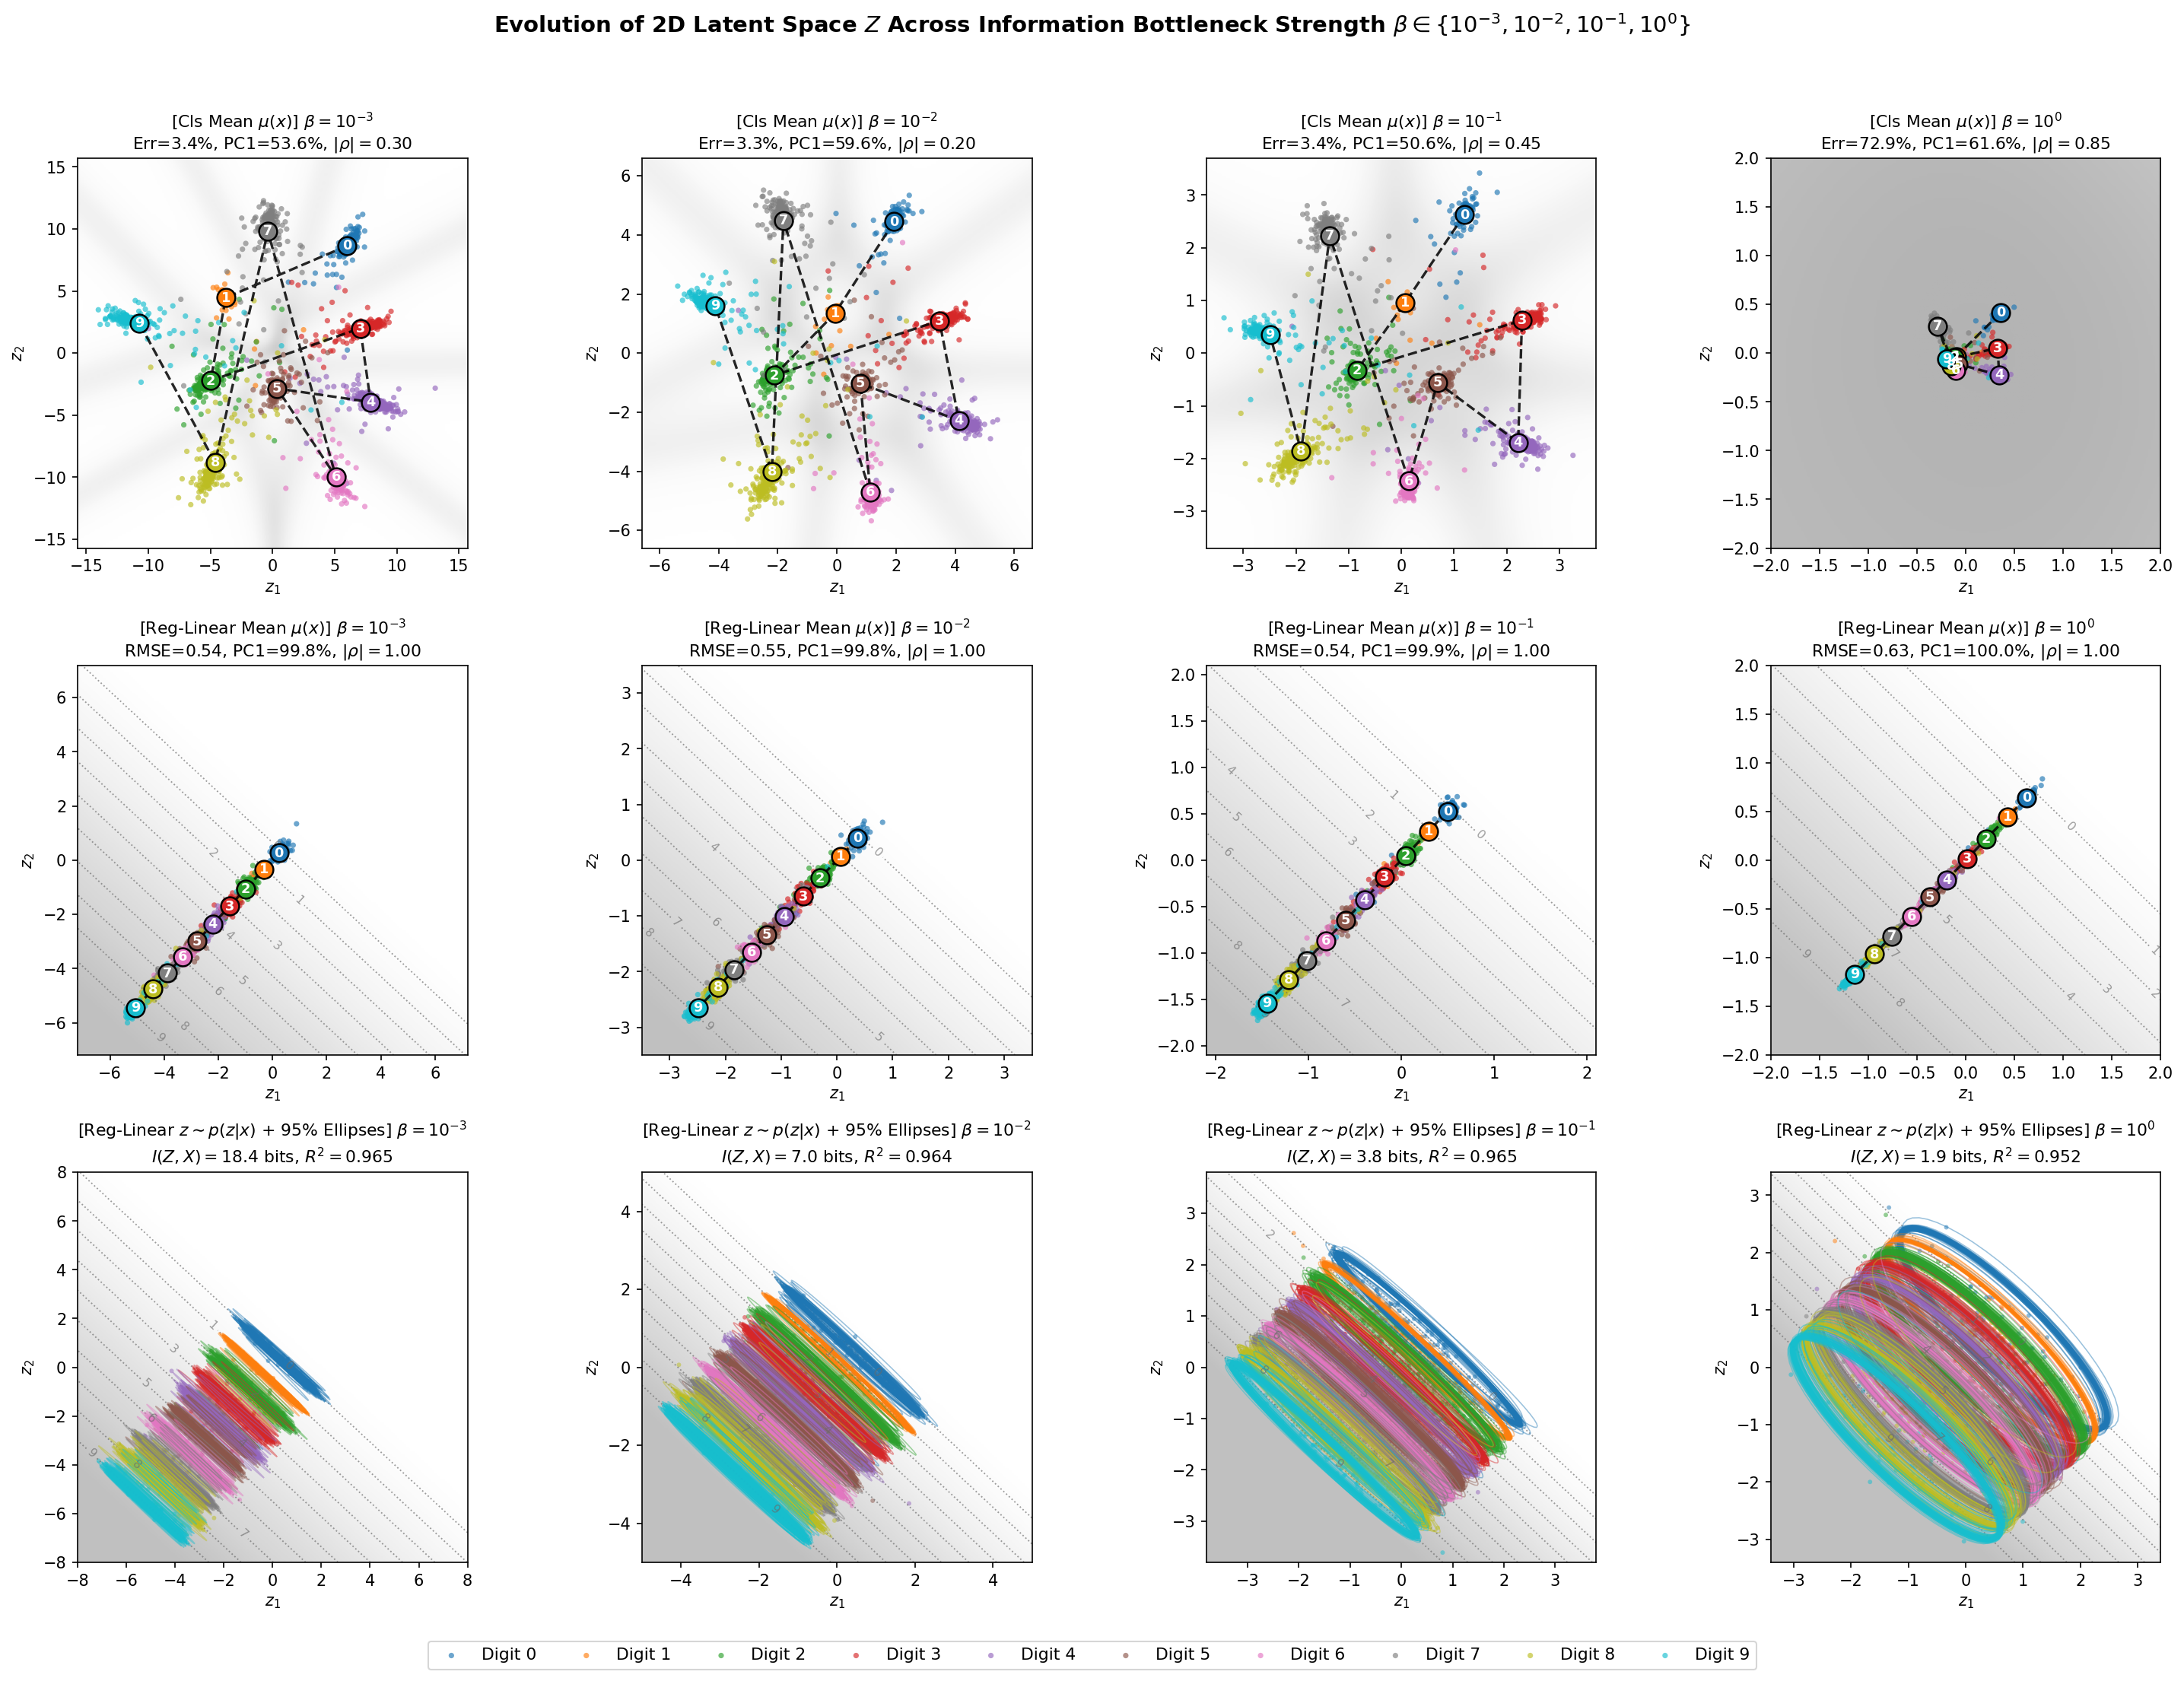

In [6]:
# 5. 図2: 正則化強度 beta の変化に伴う 2次元潜在空間 Z の散布図比較 (beta in {1e-3, 1e-2, 1e-1, 1e0})
betas_grid = [1e-3, 1e-2, 1e-1, 1e0]
fig, axes = plt.subplots(3, 4, figsize=(20.0, 14.8), dpi=180)

for col, beta in enumerate(betas_grid):
    mc = cls_metrics[beta]
    mr = reg_lin_metrics[beta]
    exp_str = f"10^{{{int(np.log10(beta))}}}"

    # Row 0: Classification Mean Scatter
    plot_latent_scatter_on_ax(
        axes[0, col], cls_models[beta], test_x, test_y,
        task_type="classification", plot_mode="mean_scatter", num_images=2000,
        title=f"[Cls Mean $\\mu(x)$] $\\beta={exp_str}$\nErr={mc['err_mc']*100:.1f}%, PC1={mc['pc1_ratio']*100:.1f}%, $|\\rho|={mc['abs_spearman']:.2f}$"
    )
    # Row 1: Regression Linear Mean Scatter
    plot_latent_scatter_on_ax(
        axes[1, col], reg_lin_models[beta], test_x, test_y,
        task_type="regression", plot_mode="mean_scatter", num_images=2000,
        title=f"[Reg-Linear Mean $\\mu(x)$] $\\beta={exp_str}$\nRMSE={mr['rmse_mc']:.2f}, PC1={mr['pc1_ratio']*100:.1f}%, $|\\rho|={mr['abs_spearman']:.2f}$"
    )
    # Row 2: Regression Linear Sample + 95% Ellipses
    plot_latent_scatter_on_ax(
        axes[2, col], reg_lin_models[beta], test_x, test_y,
        task_type="regression", plot_mode="sample_and_ellipse", num_images=1000,
        title=f"[Reg-Linear $z \\sim p(z|x)$ + 95% Ellipses] $\\beta={exp_str}$\n$I(Z,X)={mr['izx_bits']:.1f}$ bits, $R^2={mr['r2_mc']:.3f}$"
    )

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(
    handles, [f"Digit {l}" for l in labels],
    loc="lower center", ncol=10, frameon=True, fontsize=10.5, bbox_to_anchor=(0.5, 0.005)
)
fig.suptitle(
    "Evolution of 2D Latent Space $Z$ Across Information Bottleneck Strength $\\beta \\in \\{10^{-3}, 10^{-2}, 10^{-1}, 10^0\\}$",
    fontsize=14, fontweight="bold", y=0.992
)
plt.tight_layout(rect=[0.0, 0.035, 1.0, 0.97])
out_fig2 = "../report/img/ex004_reg_beta_scatter_grid.png"
plt.savefig(out_fig2, dpi=180)
plt.show()
print(f"Saved {out_fig2}")

Saved ../report/img/ex004_metrics_and_geometry.png


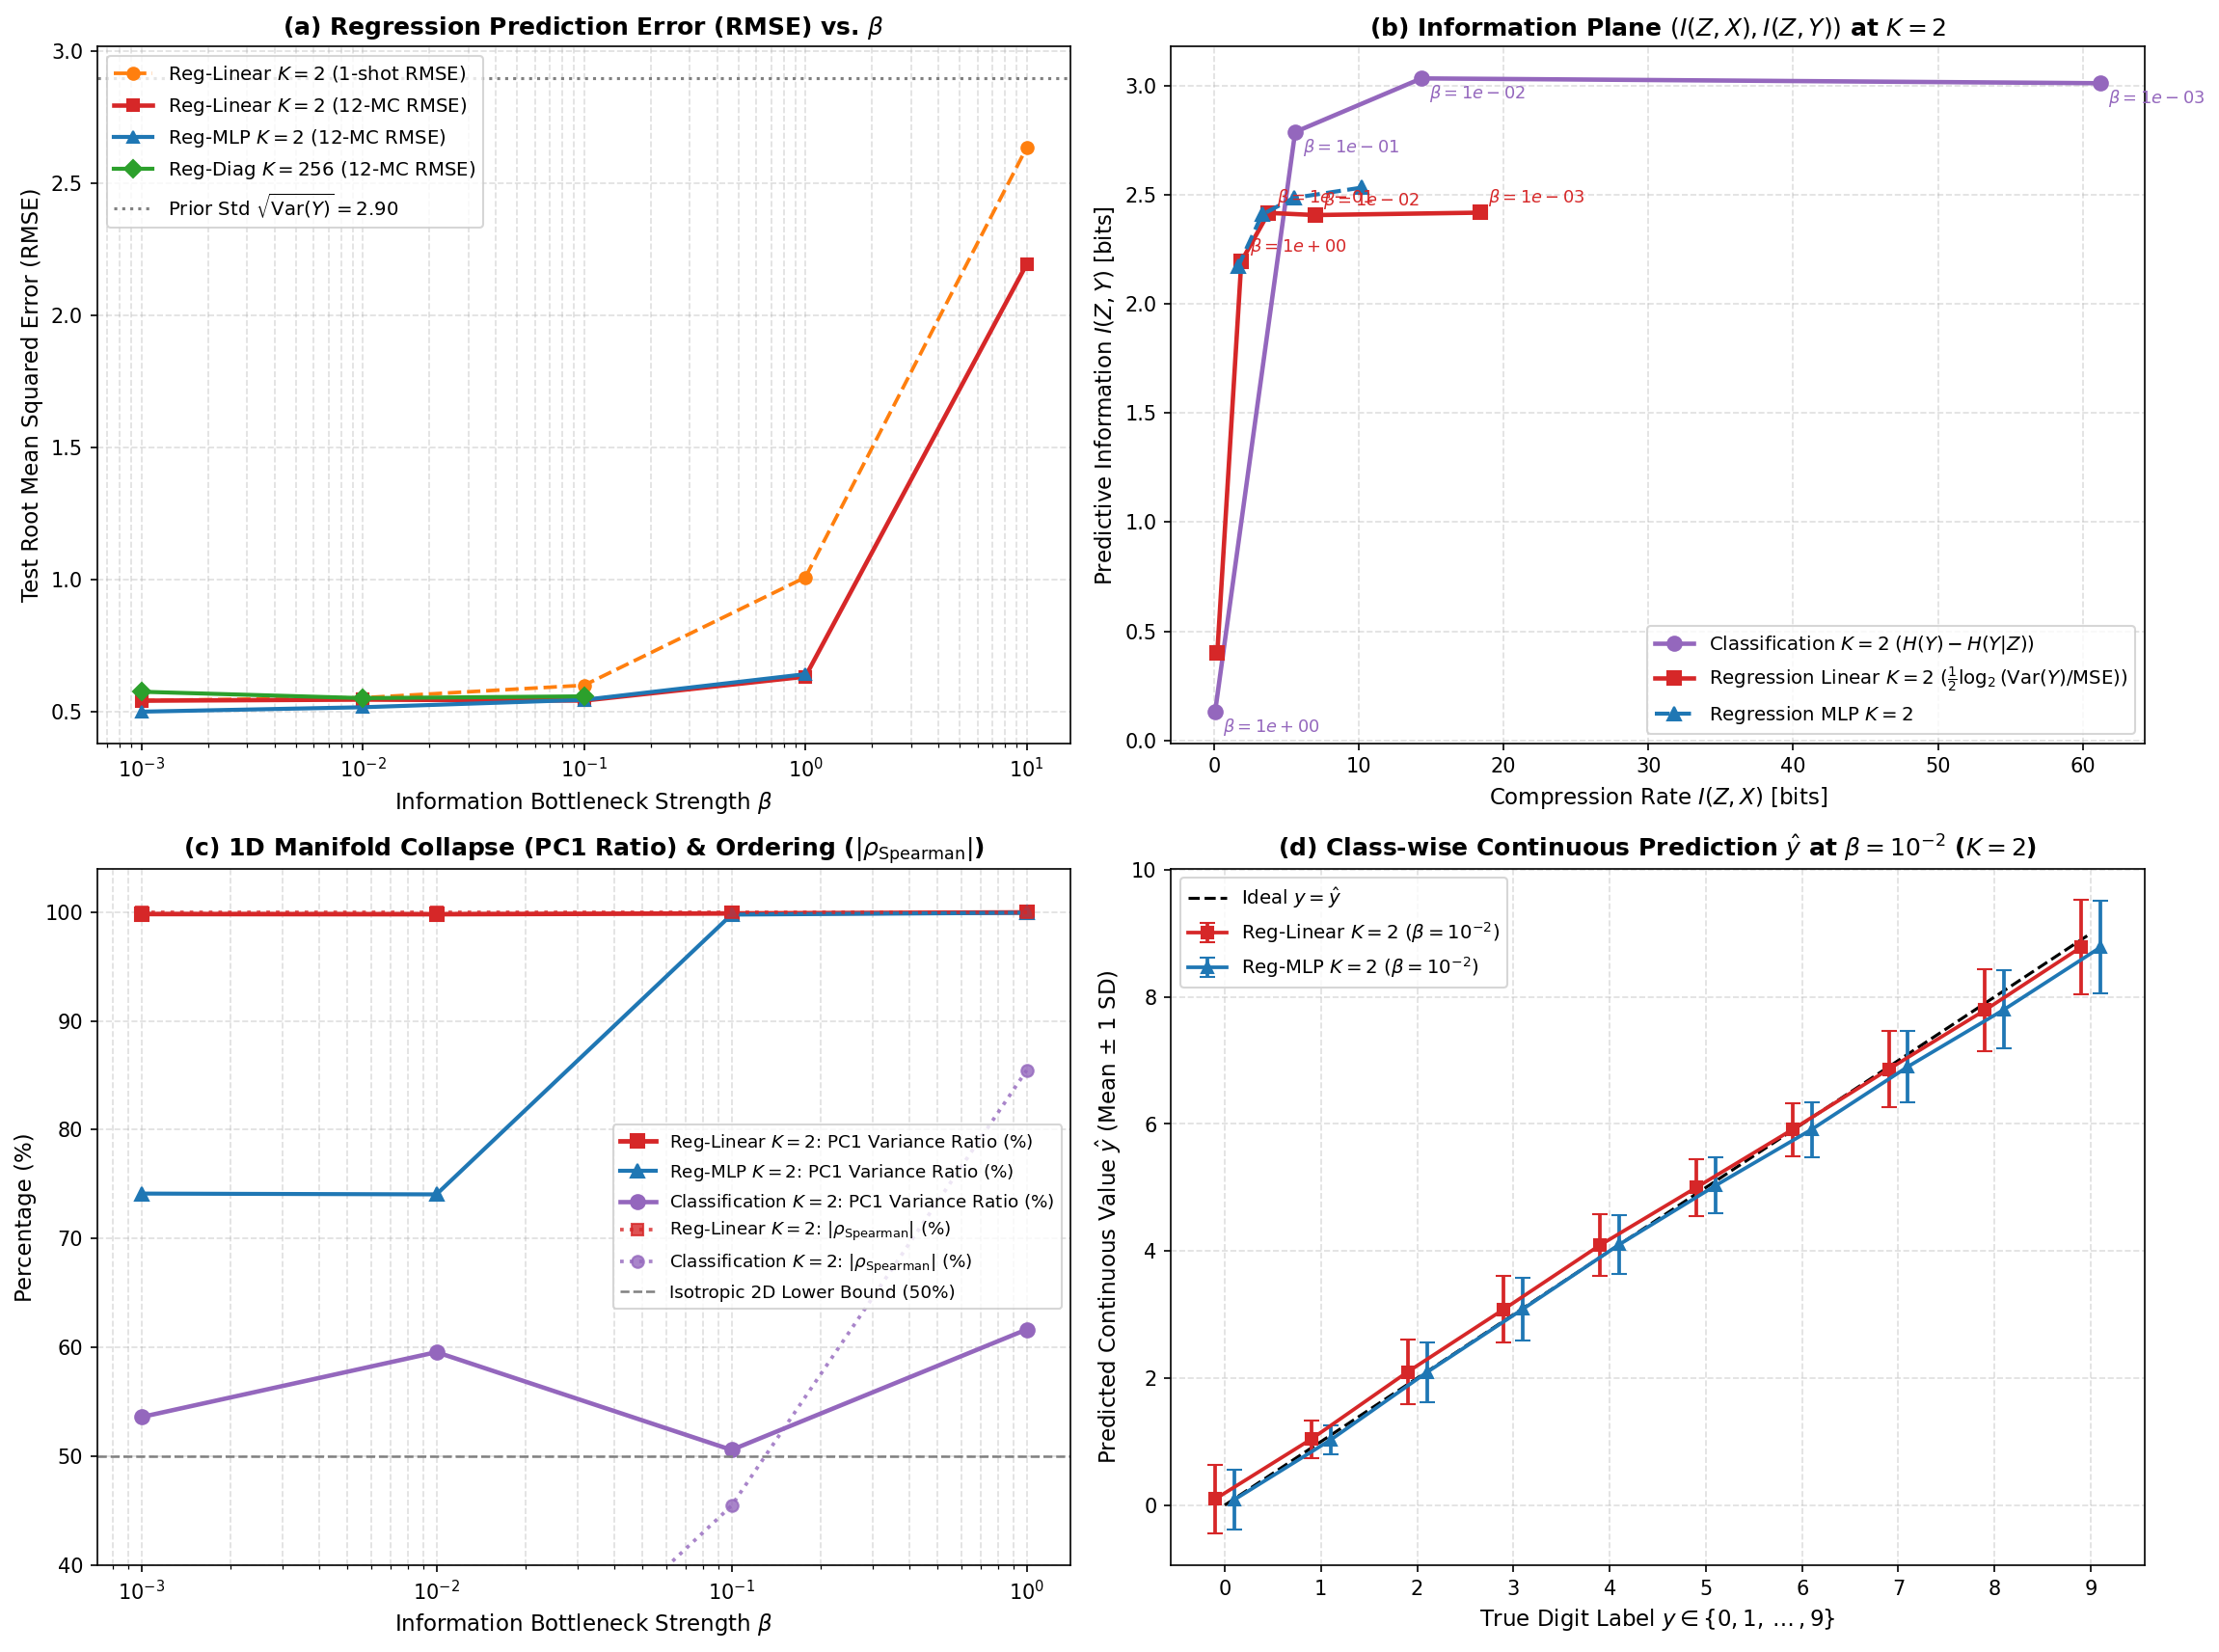

In [7]:
# 6. 図3: 回帰精度・情報量曲線・潜在空間の幾何学指標 (PC1寄与率・Spearman順位相関・数字別予測分布) の定量比較
fig, axes = plt.subplots(2, 2, figsize=(15.5, 11.5), dpi=180)

# (a) Beta vs Test RMSE & Rounded Error
ax = axes[0, 0]
b_lin = np.array(betas_reg)
rmse_lin_1sh = [reg_lin_metrics[b]["rmse_1shot"] for b in betas_reg]
rmse_lin_mc = [reg_lin_metrics[b]["rmse_mc"] for b in betas_reg]
rmse_mlp_mc = [reg_mlp_metrics[b]["rmse_mc"] for b in betas_mlp]
rmse_256_mc = [reg_k256_metrics[b]["rmse_mc"] for b in betas_k256]

ax.plot(b_lin, rmse_lin_1sh, "o--", color="#ff7f0e", lw=1.8, label="Reg-Linear $K=2$ (1-shot RMSE)")
ax.plot(b_lin, rmse_lin_mc, "s-", color="#d62728", lw=2.2, label="Reg-Linear $K=2$ (12-MC RMSE)")
ax.plot(betas_mlp, rmse_mlp_mc, "^-", color="#1f77b4", lw=2.0, label="Reg-MLP $K=2$ (12-MC RMSE)")
ax.plot(betas_k256, rmse_256_mc, "D-", color="#2ca02c", lw=2.0, label="Reg-Diag $K=256$ (12-MC RMSE)")
ax.axhline(np.sqrt(var_y_test), color="gray", ls=":", lw=1.5, label=f"Prior Std $\\sqrt{{\\mathrm{{Var}}(Y)}}={np.sqrt(var_y_test):.2f}$")
ax.set_xscale("log")
ax.set_xlabel("Information Bottleneck Strength $\\beta$", fontsize=11)
ax.set_ylabel("Test Root Mean Squared Error (RMSE)", fontsize=11)
ax.set_title("(a) Regression Prediction Error (RMSE) vs. $\\beta$", fontsize=12, fontweight="bold")
ax.grid(True, which="both", ls="--", alpha=0.4)
ax.legend(fontsize=9.5, loc="upper left")

# (b) Information Plane I(Z, X) vs I(Z, Y)
ax = axes[0, 1]
izx_cls = [cls_metrics[b]["izx_bits"] for b in betas_cls]
izy_cls = [cls_metrics[b]["izy_bits"] for b in betas_cls]
izx_rlin = [reg_lin_metrics[b]["izx_bits"] for b in betas_reg]
izy_rlin = [reg_lin_metrics[b]["izy_bits"] for b in betas_reg]
izx_rmlp = [reg_mlp_metrics[b]["izx_bits"] for b in betas_mlp]
izy_rmlp = [reg_mlp_metrics[b]["izy_bits"] for b in betas_mlp]

ax.plot(izx_cls, izy_cls, "o-", color="#9467bd", lw=2.2, markersize=7, label="Classification $K=2$ ($H(Y)-H(Y|Z)$)")
ax.plot(izx_rlin, izy_rlin, "s-", color="#d62728", lw=2.2, markersize=7, label="Regression Linear $K=2$ ($\\frac{1}{2}\\log_2(\\mathrm{Var}(Y)/\\mathrm{MSE})$)")
ax.plot(izx_rmlp, izy_rmlp, "^--", color="#1f77b4", lw=2.0, markersize=7, label="Regression MLP $K=2$")
for b in betas_cls:
    ax.annotate(f"$\\beta={b:.0e}$", (cls_metrics[b]["izx_bits"], cls_metrics[b]["izy_bits"]), textcoords="offset points", xytext=(4, -10), fontsize=8.5, color="#9467bd")
for b in betas_reg[:-1]:
    ax.annotate(f"$\\beta={b:.0e}$", (reg_lin_metrics[b]["izx_bits"], reg_lin_metrics[b]["izy_bits"]), textcoords="offset points", xytext=(4, 5), fontsize=8.5, color="#d62728")
ax.set_xlabel("Compression Rate $I(Z, X)$ [bits]", fontsize=11)
ax.set_ylabel("Predictive Information $I(Z, Y)$ [bits]", fontsize=11)
ax.set_title("(b) Information Plane $(I(Z,X), I(Z,Y))$ at $K=2$", fontsize=12, fontweight="bold")
ax.grid(True, ls="--", alpha=0.4)
ax.legend(fontsize=9.5, loc="lower right")

# (c) Latent Geometry: PC1 Contribution Ratio & Absolute Spearman Correlation vs Beta
ax = axes[1, 0]
pc1_cls = [cls_metrics[b]["pc1_ratio"] * 100.0 for b in betas_cls]
pc1_rlin = [reg_lin_metrics[b]["pc1_ratio"] * 100.0 for b in betas_cls]
pc1_rmlp = [reg_mlp_metrics[b]["pc1_ratio"] * 100.0 for b in betas_mlp]
sp_cls = [cls_metrics[b]["abs_spearman"] * 100.0 for b in betas_cls]
sp_rlin = [reg_lin_metrics[b]["abs_spearman"] * 100.0 for b in betas_cls]
sp_rmlp = [reg_mlp_metrics[b]["abs_spearman"] * 100.0 for b in betas_mlp]

ax.plot(betas_cls, pc1_rlin, "s-", color="#d62728", lw=2.3, markersize=7, label="Reg-Linear $K=2$: PC1 Variance Ratio (%)")
ax.plot(betas_mlp, pc1_rmlp, "^-", color="#1f77b4", lw=2.0, markersize=7, label="Reg-MLP $K=2$: PC1 Variance Ratio (%)")
ax.plot(betas_cls, pc1_cls, "o-", color="#9467bd", lw=2.2, markersize=7, label="Classification $K=2$: PC1 Variance Ratio (%)")
ax.plot(betas_cls, sp_rlin, "s:", color="#d62728", lw=1.8, markersize=6, alpha=0.8, label="Reg-Linear $K=2$: $|\\rho_{\\mathrm{Spearman}}|$ (%)")
ax.plot(betas_cls, sp_cls, "o:", color="#9467bd", lw=1.8, markersize=6, alpha=0.8, label="Classification $K=2$: $|\\rho_{\\mathrm{Spearman}}|$ (%)")
ax.axhline(50.0, color="gray", ls="--", lw=1.2, label="Isotropic 2D Lower Bound (50%)")
ax.set_xscale("log")
ax.set_ylim(40.0, 104.0)
ax.set_xlabel("Information Bottleneck Strength $\\beta$", fontsize=11)
ax.set_ylabel("Percentage (%)", fontsize=11)
ax.set_title("(c) 1D Manifold Collapse (PC1 Ratio) & Ordering ($|\\rho_{\\mathrm{Spearman}}|$)", fontsize=12, fontweight="bold")
ax.grid(True, which="both", ls="--", alpha=0.4)
ax.legend(fontsize=8.8, loc="center right")

# (d) Class-wise Predicted Value Distribution y_hat for Digits 0..9 (beta = 1e-2)
ax = axes[1, 1]
with torch.no_grad():
    preds_lin_mc, _, _ = reg_lin_models[1e-2](test_x, num_samples=12)
    y_hat_lin = preds_lin_mc.mean(dim=0).cpu().numpy()
    preds_mlp_mc, _, _ = reg_mlp_models[1e-2](test_x, num_samples=12)
    y_hat_mlp = preds_mlp_mc.mean(dim=0).cpu().numpy()
y_true_np = test_y.cpu().numpy()

digits = np.arange(10)
means_lin = [y_hat_lin[y_true_np == d].mean() for d in digits]
stds_lin = [y_hat_lin[y_true_np == d].std() for d in digits]
means_mlp = [y_hat_mlp[y_true_np == d].mean() for d in digits]
stds_mlp = [y_hat_mlp[y_true_np == d].std() for d in digits]

ax.plot(digits, digits, "k--", lw=1.5, label="Ideal $y = \\hat{y}$")
ax.errorbar(digits - 0.1, means_lin, yerr=stds_lin, fmt="s-", color="#d62728", lw=1.8, capsize=4, label="Reg-Linear $K=2$ ($\\beta=10^{-2}$)")
ax.errorbar(digits + 0.1, means_mlp, yerr=stds_mlp, fmt="^-", color="#1f77b4", lw=1.8, capsize=4, label="Reg-MLP $K=2$ ($\\beta=10^{-2}$)")
ax.set_xticks(digits)
ax.set_xlabel("True Digit Label $y \\in \\{0, 1, \\dots, 9\\}$", fontsize=11)
ax.set_ylabel("Predicted Continuous Value $\\hat{y}$ (Mean $\\pm$ 1 SD)", fontsize=11)
ax.set_title("(d) Class-wise Continuous Prediction $\\hat{y}$ at $\\beta=10^{-2}$ ($K=2$)", fontsize=12, fontweight="bold")
ax.grid(True, ls="--", alpha=0.4)
ax.legend(fontsize=9.5, loc="upper left")

plt.tight_layout()
out_fig3 = "../report/img/ex004_metrics_and_geometry.png"
plt.savefig(out_fig3, dpi=180)
plt.show()
print(f"Saved {out_fig3}")